# 01 · Preprocessing — Darmanis 2017 Glioblastoma (malignant compartment)

Isolate malignant cells, integrate across patient samples, and certify **Gate 1**
(sample-mixed **and** continuous). Every tunable choice is re-derived from *this* dataset
(SmartSeq2 GBM, TPM), not copied from the Puram/Lee anchors.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import warnings; warnings.filterwarnings('ignore')
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>-1  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Darmanis2017_Brain-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw input folder has no '-1' suffix (that is a re-analysis output tag)
raw_name = name[:-2] if name.endswith('-1') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', 'Data_'+raw_name)

dataset: Darmanis2017_Brain-1 | category: Brain | raw: Data_Darmanis2017_Brain


### Load malignant compartment
Darmanis et al. annotate cell type directly in `Cells.csv`; the loader sets `celltype` from it.
We keep the `Malignant` cells only. Expression is TPM (the stored matrix is already log-scale;
the loader adds `log1p`, giving compressed log values).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('X max %.2f (log1p of log-scale TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Darmanis2017_Brain
Done.
full atlas: (3589, 23368) | cell types: {'Myeloid': 1847, 'Malignant': 1091, 'OPC': 406, 'Astrocyte': 88, 'Oligodendrocyte': 85, 'Vascular': 51, 'Neuron': 21}
malignant: (1091, 23368) | samples: 4
X max 2.98 (log1p of log-scale TPM)


### Sample thresholding — gap-finding, with the atlas floor as the guard
The anchor rule finds the largest multiplicative gap in the sorted per-sample counts and keeps
samples above it. Here the counts are few and smooth: the **largest gap sits at the top of the
distribution** (531→268), so the naive rule would keep a *single* patient — which makes the Gate-1
sample-integration question unanswerable (C3: the "clean low-end gap" premise fails). All four
patients clear the atlas viability floor (≥100 malignant cells, the Puram precedent), so we keep
all four and let Harmony carry the integration.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample malignant counts:', dict(zip(n.index, n.values)))
print('adjacent ratios:', np.round(ratios,2), '| largest gap at rank', gap,
      f'({int(vals[gap])} -> {int(vals[gap+1])})')
FLOOR = 100
print(f'largest gap is at the TOP (rank {gap}); no clean low-end gap. '
      f'All {len(n)} samples >= atlas floor {FLOOR} (min {int(vals.min())}).')
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (all patients retained)')

sorted per-sample malignant counts: {'BT_S2': np.int64(531), 'BT_S1': np.int64(268), 'BT_S4': np.int64(163), 'BT_S6': np.int64(129)}
adjacent ratios: [1.98 1.64 1.26] | largest gap at rank 0 (531 -> 268)
largest gap is at the TOP (rank 0); no clean low-end gap. All 4 samples >= atlas floor 100 (min 129).
kept 4/4 samples -> 1091 cells (all patients retained)


### Overdispersion, PCA, Harmony integration, embedding
The pagoda2 overdispersion test (`scf.pp.find_overdispersed`) is calibrated for count-derived
`log1p` data; on this pre-log-transformed SmartSeq2 TPM the mean–variance GAM collapses and it
flags **1** gene (C4: format portability failure). We fall back to scanpy's standard
highly-variable selection (top 2000, Seurat flavor), which is robust on log data. `theta` is then
chosen by an **iLISI** sweep — a per-neighborhood integration metric (inverse-Simpson over the 4
samples, range 1=segregated … 4=perfectly mixed) — never a single global scalar (03_eval fork 1).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
n_od = int(adata.var['highly_variable'].sum())
print('pagoda2 overdispersed genes:', n_od, '(degenerate on pre-log TPM)')
if n_od < 500:
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat')
    print('-> scanpy HVG fallback (seurat, top 2000):', int(adata.var['highly_variable'].sum()))
sc.pp.pca(adata, n_comps=50)   # uses highly_variable automatically
vr = adata.uns['pca']['variance_ratio']
print('PCA var ratio [1..10]:', np.round(vr[:10],4))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

pagoda2 overdispersed genes: 1 (degenerate on pre-log TPM)
-> scanpy HVG fallback (seurat, top 2000): 2000
PCA var ratio [1..10]: [0.1116 0.036  0.0272 0.0236 0.0118 0.0094 0.0075 0.0072 0.006  0.0052]


In [6]:
# iLISI over the 4 samples: mean inverse-Simpson diversity of each cell's 30-NN sample labels
samp = adata.obs['sample'].values; ncat = len(set(samp)); codes = pd.Categorical(samp).codes
def ilisi(rep, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        p = np.bincount(codes[nn[i]], minlength=ncat)/k
        out[i] = 1.0/np.sum(p**2)
    return float(out.mean())
print(f'iLISI range for this dataset: 1 (segregated) .. {ncat} (perfectly mixed)')
print('PRE-Harmony  n_pcs=20 iLISI = %.2f' % ilisi(adata.obsm['X_pca'][:,:20]))
sweep = {}
for th in [1,2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = {npc: round(ilisi(adata.obsm['X_pca_harmony'][:,:npc]),2) for npc in [15,20,30]}
    print(f'theta={th:>2}:', sweep[th])
theta, n_pcs = 10, 20
print(f'selected theta={theta}, n_pcs={n_pcs} (mixing plateaus after theta=5; strongest integration without collapse)')

iLISI range for this dataset: 1 (segregated) .. 4 (perfectly mixed)
PRE-Harmony  n_pcs=20 iLISI = 1.16
2026-08-05 17:43:41,031 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:43:41,185 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:43:41,188 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 17:43:41,319 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 17:43:41,450 - harmonypy - INFO - Converged after 2 iterations
theta= 1: {15: 1.7, 20: 1.72, 30: 1.78}
2026-08-05 17:43:41,545 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:43:41,692 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:43:41,695 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 17:43:41,835 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 17:43:41,966 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 17:43:42,094 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 17:43:42,225 - harmonypy - INFO 

In [7]:
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('embedding built:', adata.obsm['X_umap'].shape, '| post-Harmony iLISI = %.2f' % ilisi(adata.obsm['X_pca_harmony'][:,:n_pcs]))

embedding built: (1091, 2) | post-Harmony iLISI = 2.68


### Remove detached islands (data-driven)
Radius graph on the UMAP at 6× the median nearest-neighbour distance; keep the largest connected
component. Strictly conservative — strips only disconnected specks.

In [8]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands removed:', int((lab!=main).sum()), 'cells in', ncomp-1, 'components')
adata = adata[lab==main].copy(); print('after island removal:', adata.shape)

detached islands removed: 0 cells in 0 components
after island removal: (1091, 18682)


### Sub-region identity — biology before the Gate-1 GO (03_eval fork 2)
A low-resolution Leiden splits the manifold into lobes. Before certifying Gate 1 we confirm each
lobe reproduces the embryonic relationships (Gast/pSom co-vary; both oppose Crest) and that Gast is
**not** confounded by proliferation — otherwise the trajectory would have to be scoped to the
lobe that behaves developmentally.

In [9]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
# quick module scores for the lobe-identity check (re-scored properly in 02)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=lab_, ctrl_as_ref=False,
                      gene_pool=list(g_ref), random_state=1234)
adata.obs['cyc_score'] = np.maximum(pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0),
                                    pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0))
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('per-lobe embryonic-relationship check (per-cell Pearson):')
for lob in sorted(adata.obs['lobe'].cat.categories):
    o = adata.obs[adata.obs['lobe']==lob]
    print(f"  lobe {lob} (n={len(o)}, cyc={o['cycling'].mean():.2f}): "
          f"Gast~pSom={np.corrcoef(o.Gast,o.pSom)[0,1]:+.2f} "
          f"Crest~Gast={np.corrcoef(o.Crest,o.Gast)[0,1]:+.2f} "
          f"Crest~pSom={np.corrcoef(o.Crest,o.pSom)[0,1]:+.2f} "
          f"Gast~cycle={np.corrcoef(o.Gast,o.cyc_score)[0,1]:+.2f}")
print('whole-manifold Gast~cellcycle r = %.2f' % np.corrcoef(adata.obs.Gast, adata.obs.cyc_score)[0,1])
print('-> all lobes reproduce the embryonic relationships; Gast not proliferation-confounded '
      '-> keep the WHOLE manifold (no scoping).')

per-lobe embryonic-relationship check (per-cell Pearson):
  lobe 0 (n=238, cyc=0.01): Gast~pSom=+0.41 Crest~Gast=-0.70 Crest~pSom=-0.62 Gast~cycle=+0.06
  lobe 1 (n=435, cyc=0.11): Gast~pSom=+0.28 Crest~Gast=-0.70 Crest~pSom=-0.59 Gast~cycle=-0.08
  lobe 2 (n=418, cyc=0.22): Gast~pSom=+0.09 Crest~Gast=-0.58 Crest~pSom=-0.55 Gast~cycle=-0.19
whole-manifold Gast~cellcycle r = -0.11
-> all lobes reproduce the embryonic relationships; Gast not proliferation-confounded -> keep the WHOLE manifold (no scoping).


### Gate 1 — batch mixing & manifold continuity
Judged on the regenerated embedding: samples must intermix (no per-patient archipelago) and the
manifold must be one connected mass.

4 patient samples share one continuous manifold (iLISI 2.68/4); radius-graph retained a single connected component.
Gate 1: samples intermixed AND manifold continuous -> GO


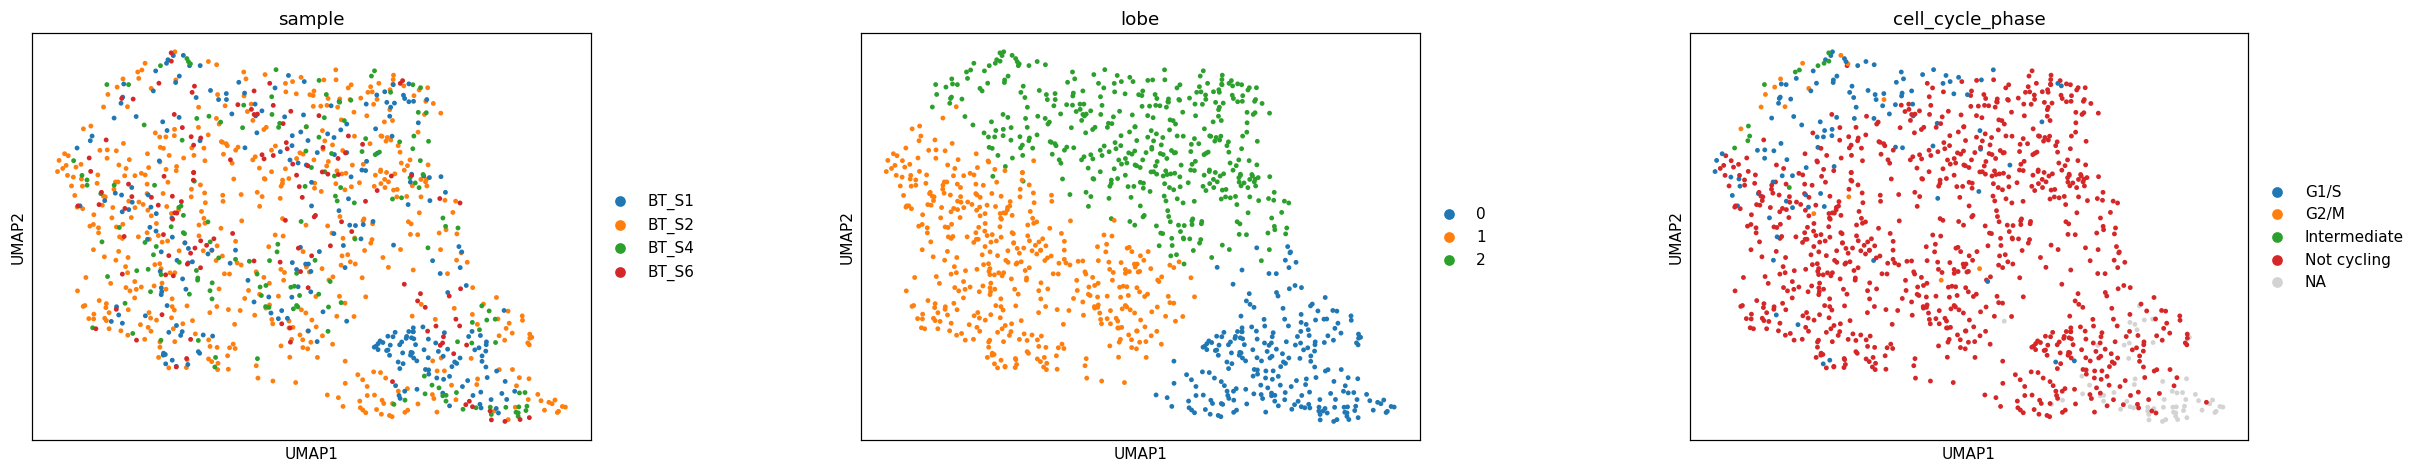

In [10]:
fig = sc.pl.umap(adata, color=['sample','lobe','cell_cycle_phase'],
                 size=40, wspace=.35, show=False)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} patient samples share one continuous manifold (iLISI {ilisi(adata.obsm["X_pca_harmony"][:,:n_pcs]):.2f}/{ncat}); '
      'radius-graph retained a single connected component.')
print('Gate 1: samples intermixed AND manifold continuous -> GO')

### Save processed data

In [11]:
for k in ['Gast','pSom','Crest']:            # drop the provisional scores; re-derived cleanly in 02
    if k in adata.obs: del adata.obs[k]
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1091, 18682)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, single sample-coloured manifold with
an external legend — the intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 1091


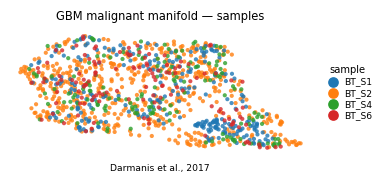

In [12]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=6, title='sample', title_fontsize=6.5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('GBM malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Darmanis et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])